In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
df = pd.read_csv('Customer Loyalty History.csv')

In [2]:
print('Shape (rows, columns):', df.shape)
df.head()

Shape (rows, columns): (16737, 16)


,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0
3,608370,Canada,Ontario,Toronto,P1W 1K4,Male,College,NaN,Single,Star,3839.75,Standard,2013,2,NaN,NaN
4,530508,Canada,Quebec,Hull,J8Y 3Z5,Male,Bachelor,103495.0,Married,Star,3842.79,Standard,2014,10,NaN,NaN


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16737 entries, 0 to 16736
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Loyalty Number      16737 non-null  int64  
 1   Country             16737 non-null  object 
 2   Province            16737 non-null  object 
 3   City                16737 non-null  object 
 4   Postal Code         16737 non-null  object 
 5   Gender              16737 non-null  object 
 6   Education           16737 non-null  object 
 7   Salary              12499 non-null  float64
 8   Marital Status      16737 non-null  object 
 9   Loyalty Card        16737 non-null  object 
 10  CLV                 16737 non-null  float64
 11  Enrollment Type     16737 non-null  object 
 12  Enrollment Year     16737 non-null  int64  
 13  Enrollment Month    16737 non-null  int64  
 14  Cancellation Year   2067 non-null   float64
 15  Cancellation Month  2067 non-null   float64
dtypes: f

In [4]:
df.describe()

,Loyalty Number,Salary,CLV,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
count,16737.000000,12499.000000,16737.000000,16737.000000,16737.000000,2067.000000,2067.000000
mean,549735.880445,79245.609409,7988.896536,2015.253211,6.669116,2016.503145,6.962748
std,258912.132453,35008.297285,6860.982280,1.979111,3.398958,1.380743,3.455297
min,100018.000000,-58486.000000,1898.010000,2012.000000,1.000000,2013.000000,1.000000
25%,326603.000000,59246.500000,3980.840000,2014.000000,4.000000,2016.000000,4.000000
50%,550434.000000,73455.000000,5780.180000,2015.000000,7.000000,2017.000000,7.000000
75%,772019.000000,88517.500000,8940.580000,2017.000000,10.000000,2018.000000,10.000000
max,999986.000000,407228.000000,83325.380000,2018.000000,12.000000,2018.000000,12.000000


In [5]:
df.isnull().sum()

Loyalty Number            0
Country                   0
Province                  0
City                      0
Postal Code               0
Gender                    0
Education                 0
Salary                 4238
Marital Status            0
Loyalty Card              0
CLV                       0
Enrollment Type           0
Enrollment Year           0
Enrollment Month          0
Cancellation Year     14670
Cancellation Month    14670
dtype: int64

In [6]:
print(df.nunique())
print()
for col in ['Country', 'Gender', 'Education', 'Marital Status', 'Enrollment Type', 'Loyalty Card']:
    print(df[col].value_counts(), '\n')

Loyalty Number        16737
Country                   1
Province                 11
City                     29
Postal Code              55
Gender                    2
Education                 5
Salary                 5890
Marital Status            3
Loyalty Card              3
CLV                    7984
Enrollment Type           2
Enrollment Year           7
Enrollment Month         12
Cancellation Year         6
Cancellation Month       12
dtype: int64

Country
Canada    16737
Name: count, dtype: int64 

Gender
Female    8410
Male      8327
Name: count, dtype: int64 

Education
Bachelor                10475
College                  4238
High School or Below      782
Doctor                    734
Master                    508
Name: count, dtype: int64 

Marital Status
Married     9735
Single      4484
Divorced    2518
Name: count, dtype: int64 

Enrollment Type
Standard          15766
2018 Promotion      971
Name: count, dtype: int64 

Loyalty Card
Star      7637
Nova      5671
Auro

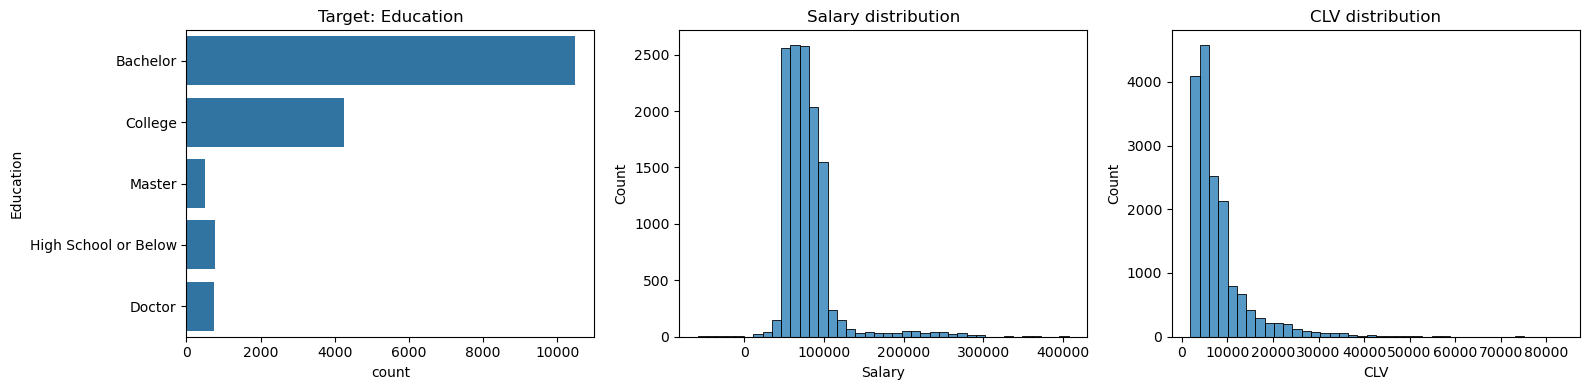

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(y='Education', data=df, ax=axes[0]);  axes[0].set_title('Target: Education')
sns.histplot(df['Salary'].dropna(), bins=40, ax=axes[1]); axes[1].set_title('Salary distribution')
sns.histplot(df['CLV'], bins=40, ax=axes[2]);            axes[2].set_title('CLV distribution')
plt.tight_layout(); plt.show()

In [8]:
data = df.copy()
data = data.drop(columns=['Loyalty Number', 'Postal Code', 'Country'])
data['Cancelled'] = data['Cancellation Year'].notnull().astype(int)
data = data.drop(columns=['Cancellation Year', 'Cancellation Month'])
data.head()

,Province,City,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancelled
0,Ontario,Toronto,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,0
1,Alberta,Edmonton,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,0
2,British Columbia,Vancouver,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,1
3,Ontario,Toronto,Male,College,NaN,Single,Star,3839.75,Standard,2013,2,0
4,Quebec,Hull,Male,Bachelor,103495.0,Married,Star,3842.79,Standard,2014,10,0


In [9]:
print('Missing before:', data['Salary'].isnull().sum())
data['Salary'] = data['Salary'].fillna(data['Salary'].median())
print('Missing after :', data['Salary'].isnull().sum())
print('Total missing values left:', data.isnull().sum().sum())

Missing before: 4238
Missing after : 0
Total missing values left: 0


Q1=63899  Q3=82940  IQR=19041  ->  valid range [35338, 111502]
Rows before: 16737 | after: 15860 | removed: 877


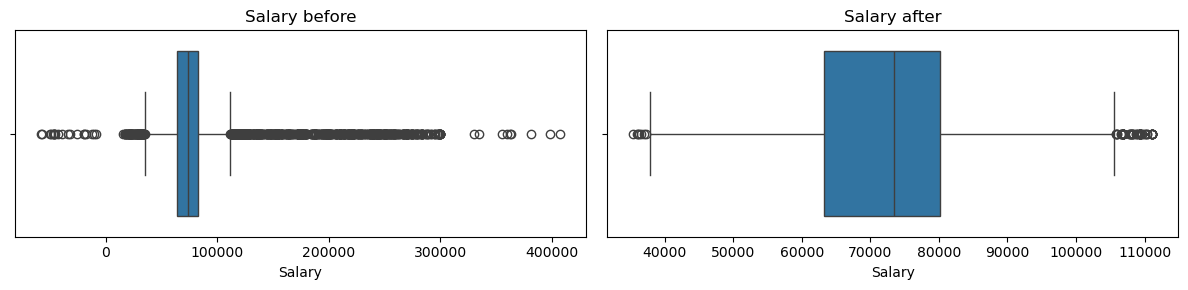

In [10]:
Q1 = data['Salary'].quantile(0.25)
Q3 = data['Salary'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
print(f'Q1={Q1:.0f}  Q3={Q3:.0f}  IQR={IQR:.0f}  ->  valid range [{lower:.0f}, {upper:.0f}]')
before = data.shape[0]
data_filtered = data[(data['Salary'] >= lower) & (data['Salary'] <= upper)]
print('Rows before:', before, '| after:', data_filtered.shape[0], '| removed:', before - data_filtered.shape[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=data['Salary'], ax=axes[0]);          axes[0].set_title('Salary before')
sns.boxplot(x=data_filtered['Salary'], ax=axes[1]); axes[1].set_title('Salary after')
plt.tight_layout(); plt.show()
data = data_filtered.reset_index(drop=True)

In [11]:
classes = ['Bachelor', 'College', 'High School or Below', 'Master', 'Doctor']                      # order used in the reports
label_map = {name: i for i, name in enumerate(classes)}
y = data['Education'].map(label_map)
print('Label mapping:', label_map)
X = data.drop(columns=['Education'])
cat_cols = X.select_dtypes(include='object').columns.tolist()
print('Categorical columns:', cat_cols)
X = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)
print('Feature matrix shape:', X.shape)
X.head()

Label mapping: {'Bachelor': 0, 'College': 1, 'High School or Below': 2, 'Master': 3, 'Doctor': 4}
Categorical columns: ['Province', 'City', 'Gender', 'Marital Status', 'Loyalty Card', 'Enrollment Type']
Feature matrix shape: (15860, 49)


,Salary,CLV,Enrollment Year,Enrollment Month,Cancelled,Province_British Columbia,Province_Manitoba,Province_New Brunswick,Province_Newfoundland,Province_Nova Scotia,...,City_West Vancouver,City_Whistler,City_Whitehorse,City_Winnipeg,Gender_Male,Marital Status_Married,Marital Status_Single,Loyalty Card_Nova,Loyalty Card_Star,Enrollment Type_Standard
0,83236.0,3839.14,2016,2,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,1
1,73455.0,3839.61,2016,3,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,1,1
2,73455.0,3839.75,2014,7,1,1,0,0,0,0,...,0,0,0,0,1,0,1,0,1,1
3,73455.0,3839.75,2013,2,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,1,1
4,103495.0,3842.79,2014,10,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,1,1


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Training set:', X_train.shape, '| Testing set:', X_test.shape)
print('\nClass share in train:\n', y_train.value_counts(normalize=True).sort_index().round(3))
print('Class share in test:\n', y_test.value_counts(normalize=True).sort_index().round(3))

Training set: (12688, 49) | Testing set: (3172, 49)

Class share in train:
 Education
0    0.655
1    0.267
2    0.049
3    0.019
4    0.009
Name: proportion, dtype: float64
Class share in test:
 Education
0    0.655
1    0.267
2    0.049
3    0.019
4    0.009
Name: proportion, dtype: float64


In [14]:
num_cols = ['Salary', 'CLV', 'Enrollment Year', 'Enrollment Month']
scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   
X_test_s[num_cols]  = scaler.transform(X_test[num_cols])    
X_train_s[num_cols].describe().loc[['mean', 'std']].round(3)

,Salary,CLV,Enrollment Year,Enrollment Month
mean,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0


In [15]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_s, y_train)
print('Both models trained successfully.')

Both models trained successfully.


In [16]:
models = {'Logistic Regression': log_reg, 'Random Forest': rf}
results = {}
for name, model in models.items():
    pred = model.predict(X_test_s)
    acc = accuracy_score(y_test, pred)
    results[name] = acc
    print('=' * 60)
    print(f'{name}  |  Accuracy = {acc:.4f}')
    print('=' * 60)
    print(classification_report(y_test, pred, target_names=classes, digits=3))

Logistic Regression  |  Accuracy = 0.6983
                      precision    recall  f1-score   support

            Bachelor      0.751     0.835     0.791      2078
             College      0.554     0.560     0.557       848
High School or Below      0.000     0.000     0.000       155
              Master      1.000     0.082     0.152        61
              Doctor      0.000     0.000     0.000        30

            accuracy                          0.698      3172
           macro avg      0.461     0.295     0.300      3172
        weighted avg      0.659     0.698     0.670      3172

Random Forest  |  Accuracy = 0.9284
                      precision    recall  f1-score   support

            Bachelor      0.904     0.998     0.949      2078
             College      0.994     1.000     0.997       848
High School or Below      0.882     0.097     0.174       155
              Master      1.000     0.148     0.257        61
              Doctor      0.000     0.000     0.00

D:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
D:\ProgramData\anaconda3\Lib\site-packag

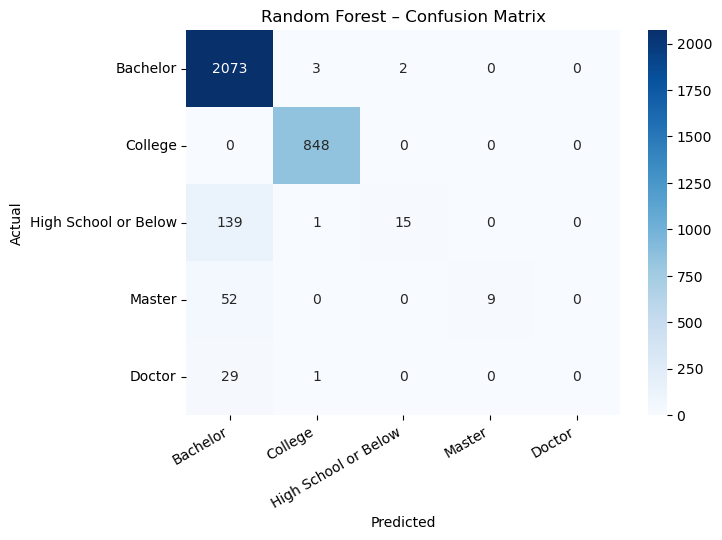

In [17]:
y_pred = rf.predict(X_test_s)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xticks(rotation=30, ha='right')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Random Forest – Confusion Matrix')
plt.show()

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances.sort_values().plot(kind='barh', figsize=(7, 4), title='Top 10 feature importances (Random Forest)')
plt.tight_layout(); plt.show()